# Semana 13 — Redes neuronales artificiales: diabetes

Ejecute en Google Colab. Suba `diabetes_data_es_GOLD.csv` al panel Archivos del entorno. El entrenamiento y los experimentos producen resultados reales al ejecutar las celdas. La clase positiva es `Positivo` (1). La evaluación repetida en test es exploratoria y no constituye una evaluación final independiente después de seleccionar hiperparámetros.


In [1]:
import os, random, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import joblib
from IPython.display import display
print('TensorFlow:', tf.__version__)


TensorFlow: 2.21.0


## 1. Carga, estadísticas y correlación
La variable objetivo se codifica exclusivamente para el análisis y el entrenamiento: Negativo = 0, Positivo = 1. La correlación no implica causalidad.

Dimensiones: (520, 17) 
Clases:
 TieneDiabetes
Positivo    320
Negativo    200
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Edad,520.0,48.028846,12.151466,16.0,39.0,47.5,57.0,90.0
Genero,520.0,0.630769,0.483061,0.0,0.0,1.0,1.0,1.0
Poliuria,520.0,0.496154,0.500467,0.0,0.0,0.0,1.0,1.0
Polidipsia,520.0,0.448077,0.497776,0.0,0.0,0.0,1.0,1.0
Perdida_repentina_peso,520.0,0.417308,0.493589,0.0,0.0,0.0,1.0,1.0
Debilidad,520.0,0.586538,0.492928,0.0,0.0,1.0,1.0,1.0
Polifagia,520.0,0.455769,0.498519,0.0,0.0,0.0,1.0,1.0
Candidiasis_genital,520.0,0.223077,0.416710,0.0,0.0,0.0,0.0,1.0
Vision_borrosa,520.0,0.448077,0.497776,0.0,0.0,0.0,1.0,1.0
Picazon,520.0,0.486538,0.500300,0.0,0.0,0.0,1.0,1.0


,TieneDiabetes_binaria
TieneDiabetes_binaria,1.000000
Poliuria,0.665922
Polidipsia,0.648734
Perdida_repentina_peso,0.436568
Paresia_parcial,0.432288
Polifagia,0.342504
Irritabilidad,0.299467
Vision_borrosa,0.251300
Debilidad,0.243275
Rigidez_muscular,0.122474


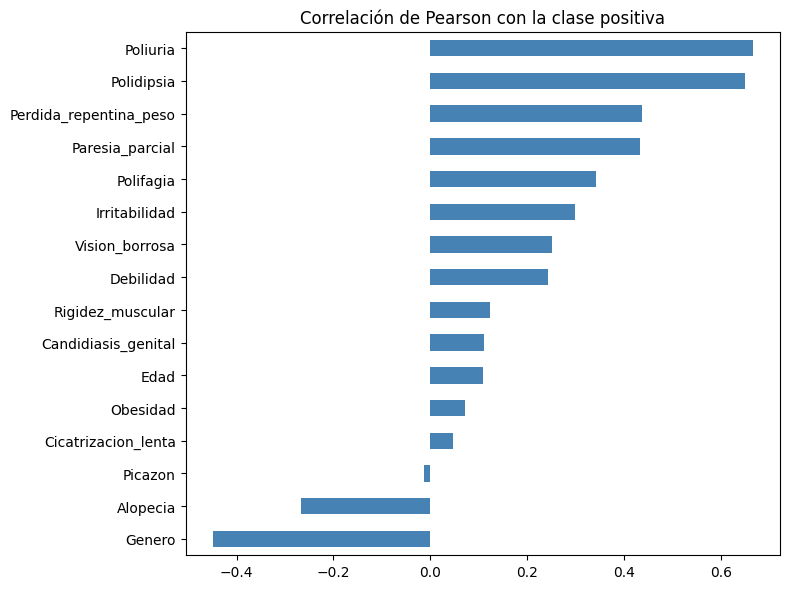

In [2]:
ruta = Path('diabetes_data_es_GOLD.csv')
if not ruta.exists():
    raise FileNotFoundError('Suba diabetes_data_es_GOLD.csv al panel Archivos de Colab y vuelva a ejecutar esta celda.')
df = pd.read_csv(ruta)
features = ['Edad','Genero','Poliuria','Polidipsia','Perdida_repentina_peso','Debilidad',
            'Polifagia','Candidiasis_genital','Vision_borrosa','Picazon','Irritabilidad',
            'Cicatrizacion_lenta','Paresia_parcial','Rigidez_muscular','Alopecia','Obesidad']
assert list(df.columns) == features + ['TieneDiabetes'], 'Revise columnas y orden del CSV.'
assert set(df.TieneDiabetes.unique()) == {'Negativo','Positivo'}
assert not df.isna().any().any(), 'Hay valores faltantes; revíselos antes de continuar.'
X = df[features].copy()
y = df.TieneDiabetes.map({'Negativo':0, 'Positivo':1})
print('Dimensiones:', df.shape, '\nClases:\n', df.TieneDiabetes.value_counts())
display(df.describe().T)
df.describe().T.to_csv('estadisticas_descriptivas.csv', encoding='utf-8-sig')
corr = X.assign(TieneDiabetes_binaria=y).corr()
corr.to_csv('correlacion_pearson.csv', encoding='utf-8-sig')
display(corr[['TieneDiabetes_binaria']].sort_values('TieneDiabetes_binaria', ascending=False))
plt.figure(figsize=(8,6))
corr['TieneDiabetes_binaria'].drop('TieneDiabetes_binaria').sort_values().plot.barh(color='steelblue')
plt.title('Correlación de Pearson con la clase positiva'); plt.tight_layout()
plt.savefig('correlacion.png', dpi=150); plt.show()


## 2. Partición, entrenamiento y comparación
La partición base es 80/20 estratificada, semilla 42. Del 80% se reserva un 15% para validación. El escalador se ajusta únicamente con los datos de entrenamiento, evitando fuga hacia validación o test. Las arquitecturas usan ReLU y Adam según la opción Python de la guía; no son el algoritmo RProp de KNIME.

In [3]:
def particionar(test_size=0.20, seed=42, cols=None):
    cols = list(cols if cols is not None else features)
    xa, xt, ya, yt = train_test_split(X[cols], y, test_size=test_size, random_state=seed, stratify=y)
    xtr, xv, ytr, yv = train_test_split(xa, ya, test_size=0.15, random_state=seed, stratify=ya)
    sc = StandardScaler().fit(xtr)
    return sc.transform(xtr), sc.transform(xv), sc.transform(xt), ytr, yv, yt, sc

def semilla(seed):
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)

def entrenar_rna(data, hidden=(32,16), seed=42):
    xtr, xv, xt, ytr, yv, yt, sc = data
    keras.backend.clear_session(); semilla(seed)
    red = keras.Sequential([keras.Input(shape=(xtr.shape[1],))])
    for i, units in enumerate(hidden):
        red.add(layers.Dense(units, activation='relu'))
        if i == 0: red.add(layers.Dropout(0.3))
        elif i == 1: red.add(layers.Dropout(0.2))
    red.add(layers.Dense(1, activation='sigmoid'))
    red.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    t = time.perf_counter()
    hist = red.fit(xtr, ytr, validation_data=(xv,yv), epochs=100, batch_size=32,
                   callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=15,restore_best_weights=True)], verbose=0)
    return red, hist, time.perf_counter()-t

def entrenar_gbt(data, n=100, lr=0.1, seed=42):
    xtr, xv, xt, ytr, yv, yt, sc = data
    m = GradientBoostingClassifier(n_estimators=n, max_depth=5, learning_rate=lr, random_state=seed)
    t=time.perf_counter(); m.fit(xtr,ytr)
    return m, time.perf_counter()-t

def metricas(modelo, data, tipo, segundos, variante, epochs=None):
    xtr, xv, xt, ytr, yv, yt, sc = data
    def probs(x):
        return modelo.predict(x, verbose=0).ravel() if tipo == 'RNA' else modelo.predict_proba(x)[:,1]
    ptr, pv, pt = probs(xtr), probs(xv), probs(xt)
    pred=(pt >= 0.5).astype(int)
    return {'Experimento':variante,'Modelo':tipo,'Train accuracy':accuracy_score(ytr,ptr>=0.5),
            'Val accuracy':accuracy_score(yv,pv>=0.5),'Test accuracy':accuracy_score(yt,pred),
            'F1':f1_score(yt,pred,zero_division=0),'AUC':roc_auc_score(yt,pt),
            'Épocas':epochs,'Tiempo s':segundos}, pt, pred

base = particionar()
print('Entrenamiento / validación / test:', len(base[3]),len(base[4]),len(base[5]))
rna, historia, tiempo_rna = entrenar_rna(base)
gbt, tiempo_gbt = entrenar_gbt(base)
rna.summary()
res_rna, prob_rna, pred_rna = metricas(rna,base,'RNA',tiempo_rna,'Base RNA [32,16]',len(historia.history['loss']))
res_gbt, prob_gbt, pred_gbt = metricas(gbt,base,'GBT',tiempo_gbt,'Base GBT 100 árboles')
comparacion = pd.DataFrame([res_rna,res_gbt])
display(comparacion.round(4))
comparacion.to_csv('comparacion_modelos.csv',index=False,encoding='utf-8-sig')
rna.save('modelo_rna.keras'); joblib.dump(base[6],'scaler.pkl')


Entrenamiento / validación / test: 353 63 104


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,269 (12.77 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,180 (8.52 KB)

,Experimento,Modelo,Train accuracy,Val accuracy,Test accuracy,F1,AUC,Épocas,Tiempo s
0,"Base RNA [32,16]",RNA,0.9858,0.9365,0.9519,0.9600,0.9984,91.0,12.7201
1,Base GBT 100 árboles,GBT,1.0000,0.9683,0.9904,0.9921,0.9867,NaN,0.2649


['scaler.pkl']

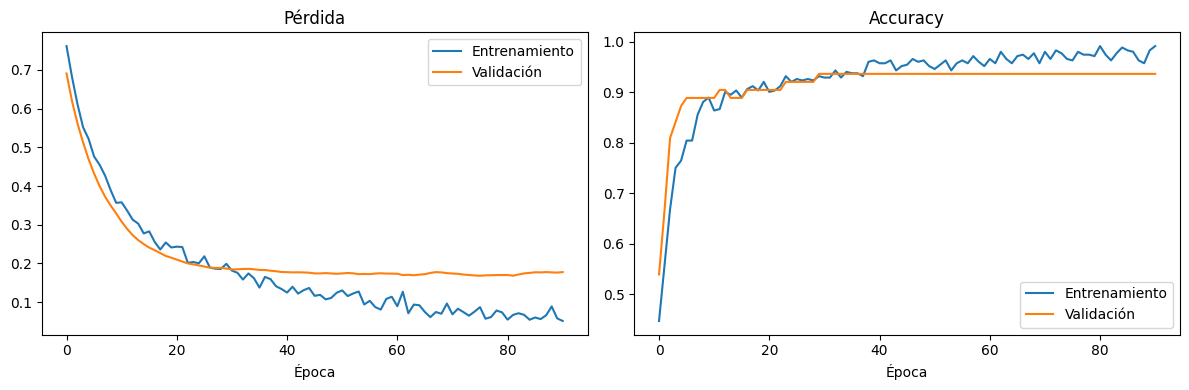

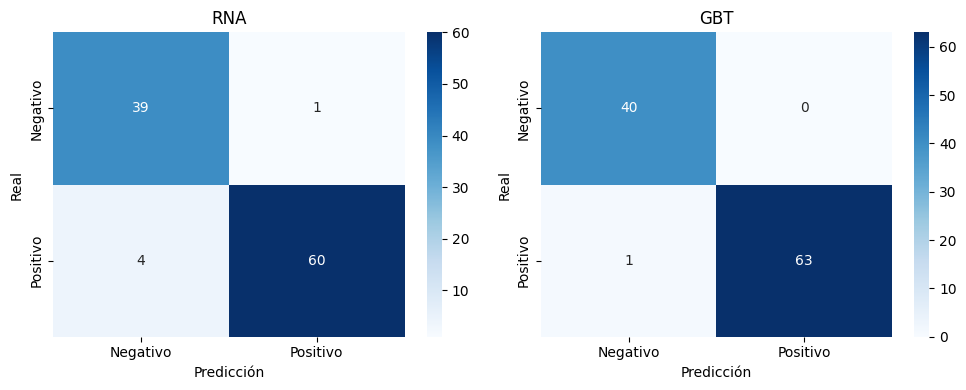

In [4]:
fig, ax = plt.subplots(1,2,figsize=(12,4))
for i, (key,title) in enumerate([('loss','Pérdida'),('accuracy','Accuracy')]):
    ax[i].plot(historia.history[key],label='Entrenamiento')
    ax[i].plot(historia.history['val_'+key],label='Validación')
    ax[i].set_title(title); ax[i].set_xlabel('Época'); ax[i].legend()
plt.tight_layout(); plt.savefig('curva_aprendizaje.png',dpi=150); plt.show()
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, pred, title in zip(axes,[pred_rna,pred_gbt],['RNA','GBT']):
    cm=confusion_matrix(base[5],pred,labels=[0,1])
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',ax=ax,xticklabels=['Negativo','Positivo'],yticklabels=['Negativo','Positivo'])
    ax.set_title(title); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig('matrices_confusion.png',dpi=150); plt.show()


## 3. Desafíos experimentales
Cada variante cambia un factor respecto de su modelo base. Se registra el tiempo de entrenamiento; las épocas son las efectivamente ejecutadas. La variación de semillas cambia también la partición y el entrenamiento. Para la ablación se entrena de nuevo la RNA sin cada variable, manteniendo la partición y semilla. La última celda puede tardar varios minutos.

,Experimento,Modelo,Train accuracy,Val accuracy,Test accuracy,F1,AUC,Épocas,Tiempo s
0,"Base RNA [32,16]",RNA,0.9858,0.9365,0.9519,0.9600,0.9984,91.0,12.7201
1,Base GBT 100 árboles,GBT,1.0000,0.9683,0.9904,0.9921,0.9867,NaN,0.2649
2,"Capas [64, 32, 16]",RNA,0.9802,0.9365,0.9712,0.9764,0.9969,46.0,9.1871
3,"Capas [128, 64, 32, 16]",RNA,0.9858,0.9524,0.9712,0.9764,0.9980,34.0,7.0020
4,Partición train/test 50%/50%,RNA,0.9910,0.8974,0.9385,0.9490,0.9836,83.0,10.4582
5,Partición train/test 70%/30%,RNA,0.9838,0.9455,0.9487,0.9579,0.9901,67.0,8.6196
6,Partición train/test 90%/10%,RNA,0.9899,0.9718,1.0000,1.0000,1.0000,88.0,12.7323
7,Partición train/test 95%/5%,RNA,0.9857,0.9467,1.0000,1.0000,1.0000,88.0,13.2448
8,GBT árboles=10,GBT,0.9830,0.9683,0.9808,0.9841,0.9844,NaN,0.0342
9,GBT árboles=50,GBT,1.0000,0.9683,0.9904,0.9921,0.9855,NaN,0.1821


,mean,std
Modelo,,
GBT,0.980769,0.009615
RNA,0.965385,0.022136


,Experimento,Modelo,Train accuracy,Val accuracy,Test accuracy,F1,AUC,Épocas,Tiempo s,Caída accuracy frente a base
29,Sin Polidipsia,RNA,0.9773,0.9365,0.9615,0.9683,0.9922,100.0,14.0246,-0.0096
30,Sin Perdida_repentina_peso,RNA,0.9830,0.9524,0.9615,0.9683,0.9953,67.0,10.0707,-0.0096
41,Sin Obesidad,RNA,0.9802,0.9365,0.9615,0.9683,0.9980,79.0,11.4862,-0.0096
37,Sin Cicatrizacion_lenta,RNA,0.9943,0.9524,0.9615,0.9683,0.9988,100.0,13.8998,-0.0096
38,Sin Paresia_parcial,RNA,0.9830,0.9524,0.9615,0.9683,0.9969,81.0,11.6142,-0.0096
40,Sin Alopecia,RNA,0.9830,0.9365,0.9615,0.9683,0.9984,100.0,13.6681,-0.0096
27,Sin Genero,RNA,0.9830,0.9206,0.9712,0.9760,0.9941,100.0,14.6573,-0.0192
26,Sin Edad,RNA,0.9943,0.9683,0.9712,0.9764,0.9969,84.0,11.9699,-0.0192
33,Sin Candidiasis_genital,RNA,0.9943,0.9524,0.9712,0.9764,0.9988,95.0,13.4465,-0.0192
32,Sin Polifagia,RNA,0.9773,0.9524,0.9712,0.9764,0.9977,76.0,11.3546,-0.0192


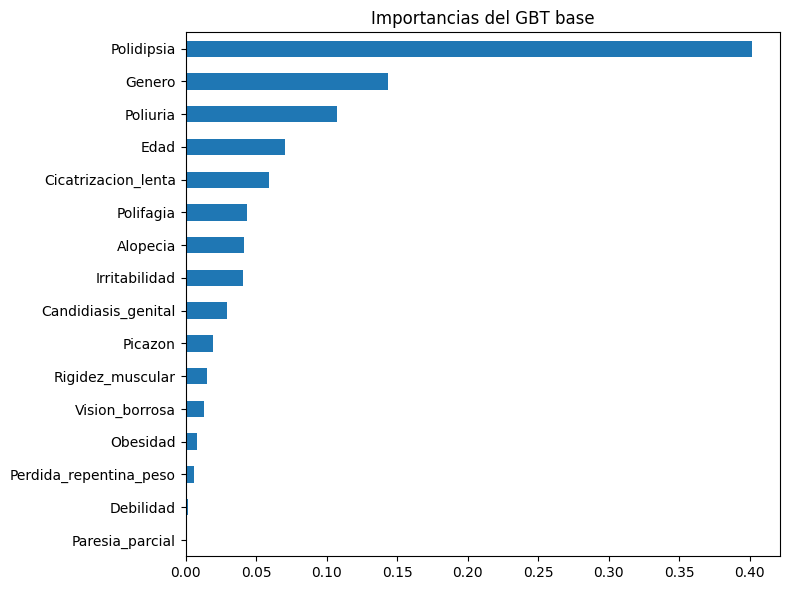

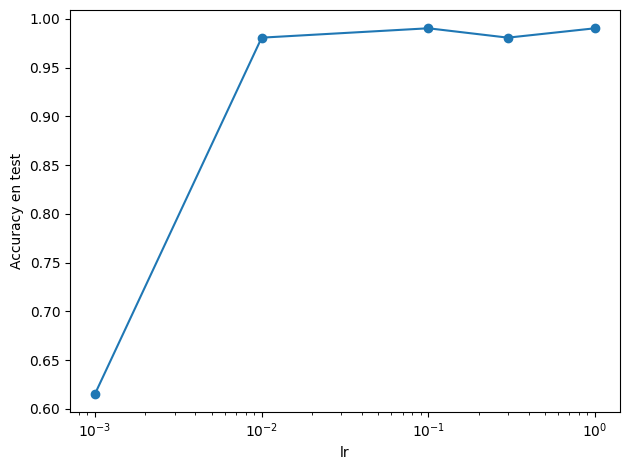

In [5]:
registros = [res_rna, res_gbt]
for arquitectura in [(64,32,16),(128,64,32,16)]:
    m,h,t=entrenar_rna(base,hidden=arquitectura)
    registros.append(metricas(m,base,'RNA',t,f'Capas {list(arquitectura)}',len(h.history['loss']))[0])
for fraccion in [0.50,0.30,0.10,0.05]:
    d=particionar(test_size=fraccion)
    m,h,t=entrenar_rna(d)
    registros.append(metricas(m,d,'RNA',t,f'Partición train/test {1-fraccion:.0%}/{fraccion:.0%}',len(h.history['loss']))[0])
for n in [10,50,200,500]:
    m,t=entrenar_gbt(base,n=n)
    registros.append(metricas(m,base,'GBT',t,f'GBT árboles={n}')[0])
for lr in [0.001,0.01,0.3,1.0]:
    m,t=entrenar_gbt(base,lr=lr)
    registros.append(metricas(m,base,'GBT',t,f'GBT learning_rate={lr}')[0])
for seed in [0,7,21,42,99]:
    d=particionar(seed=seed)
    m,h,t=entrenar_rna(d,seed=seed)
    registros.append(metricas(m,d,'RNA',t,f'Semilla {seed}',len(h.history['loss']))[0])
    m,t=entrenar_gbt(d,seed=seed)
    registros.append(metricas(m,d,'GBT',t,f'Semilla {seed}')[0])
for col in features:
    d=particionar(cols=[f for f in features if f != col])
    m,h,t=entrenar_rna(d)
    registros.append(metricas(m,d,'RNA',t,f'Sin {col}',len(h.history['loss']))[0])
tabla=pd.DataFrame(registros)
tabla.to_csv('tabla_experimentos.csv',index=False,encoding='utf-8-sig')
display(tabla.round(4))
semillas=tabla[tabla.Experimento.str.startswith('Semilla')]
display(semillas.groupby('Modelo')['Test accuracy'].agg(['mean','std']))
ablacion=tabla[tabla.Experimento.str.startswith('Sin ')].copy()
ablacion['Caída accuracy frente a base']=res_rna['Test accuracy']-ablacion['Test accuracy']
display(ablacion.sort_values('Caída accuracy frente a base',ascending=False).round(4))
importancias=pd.Series(gbt.feature_importances_,index=features).sort_values()
importancias.plot.barh(figsize=(8,6),title='Importancias del GBT base')
plt.tight_layout(); plt.savefig('importancia_variables.png',dpi=150); plt.show()
lr_rows=tabla[(tabla.Modelo=='GBT') & tabla.Experimento.str.startswith('GBT learning_rate=')].copy()
lr_rows=pd.concat([lr_rows,pd.DataFrame([dict(res_gbt,Experimento='GBT learning_rate=0.1')])])
lr_rows['lr']=lr_rows.Experimento.str.split('=').str[-1].astype(float)
lr_rows.sort_values('lr').plot(x='lr',y='Test accuracy',logx=True,marker='o',legend=False)
plt.ylabel('Accuracy en test'); plt.tight_layout(); plt.savefig('accuracy_learning_rate.png',dpi=150); plt.show()


## 4. Interpretación y entrega
- Registre las observaciones apoyándose en los resultados que aparecen arriba; compare las curvas de pérdida para explorar sobreajuste.
- El test de 5% contiene pocas observaciones; sus métricas pueden variar considerablemente. No existe un tamaño mínimo universal que garantice precisión.
- Las importancias del GBT y las caídas por ablación son medidas distintas; la ablación puede variar por aleatoriedad y correlación entre variables.
- Descargue los archivos generados, el notebook ejecutado y las capturas. Consulte `LEEME.md` para publicar Streamlit y preparar el informe.


In [6]:
# Auditoría de datos duplicados
from sklearn.model_selection import train_test_split
import pandas as pd

idx_desarrollo, idx_test = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=y
)
idx_train, idx_val = train_test_split(
    idx_desarrollo, test_size=0.15, random_state=42, stratify=y.loc[idx_desarrollo]
)
def firmas(indices):
    return set(map(tuple, df.loc[indices, features].to_numpy()))
train_f, val_f, test_f = map(firmas, [idx_train, idx_val, idx_test])
print('Filas duplicadas completas:', int(df.duplicated().sum()))
print('Firmas distintas de test que aparecen en entrenamiento:', len(test_f & train_f))
print('Firmas distintas de test que aparecen en desarrollo (train o validación):', len(test_f & (train_f | val_f)))
print('Filas de test con una firma presente en desarrollo:',
      sum(tuple(row) in (train_f | val_f) for row in df.loc[idx_test, features].to_numpy()))
print('Filas de test:', len(idx_test))


Filas duplicadas completas: 269
Firmas distintas de test que aparecen en entrenamiento: 54
Firmas distintas de test que aparecen en desarrollo (train o validación): 56
Filas de test con una firma presente en desarrollo: 72
Filas de test: 104


Entrenamiento : 347 filas; clases: {0: 127, 1: 220}
Validación : 64 filas; clases: {0: 21, 1: 43}
Prueba : 109 filas; clases: {0: 52, 1: 57}
Grupos compartidos entre particiones: 0


,Experimento,Modelo,Train accuracy,Val accuracy,Test accuracy,F1,AUC,Épocas,Tiempo s
0,"RNA base, grupos separados",RNA,0.9683,0.9375,0.9083,0.9153,0.9737,46.0,9.1982
1,"GBT base, grupos separados",GBT,1.0000,0.9844,0.9358,0.9412,0.9686,NaN,0.2404


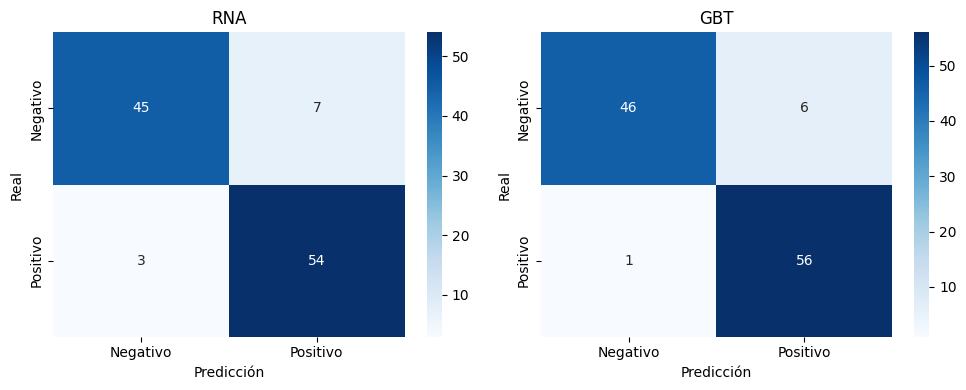

Guardados comparacion_sin_solapamiento.csv y matrices_sin_solapamiento.png
Los archivos modelo_rna.keras y scaler.pkl originales no se han modificado.


In [7]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cada combinación de predictores forma un grupo, sin usar la etiqueta para agrupar.
grupos = pd.factorize(pd.MultiIndex.from_frame(X[features]))[0]
separador_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dev_pos, test_pos = next(separador_test.split(X, y, groups=grupos))
separador_val = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
tr_rel, val_rel = next(separador_val.split(X.iloc[dev_pos], y.iloc[dev_pos], groups=grupos[dev_pos]))
tr_pos, val_pos = dev_pos[tr_rel], dev_pos[val_rel]

gr_tr, gr_val, gr_test = map(lambda pos: set(grupos[pos]), [tr_pos, val_pos, test_pos])
assert not (gr_tr & gr_val or gr_tr & gr_test or gr_val & gr_test), 'Se detectó solapamiento de grupos.'
for nombre, pos in [('Entrenamiento', tr_pos), ('Validación', val_pos), ('Prueba', test_pos)]:
    print(nombre, ':', len(pos), 'filas; clases:', y.iloc[pos].value_counts().sort_index().to_dict())
    assert y.iloc[pos].nunique() == 2, f'La partición {nombre} no contiene ambas clases.'
print('Grupos compartidos entre particiones: 0')

sc_agrupado = StandardScaler().fit(X.iloc[tr_pos])
datos_agrupados = (
    sc_agrupado.transform(X.iloc[tr_pos]),
    sc_agrupado.transform(X.iloc[val_pos]),
    sc_agrupado.transform(X.iloc[test_pos]),
    y.iloc[tr_pos], y.iloc[val_pos], y.iloc[test_pos], sc_agrupado
)
rna_grupos, hist_grupos, tiempo_rna_grupos = entrenar_rna(datos_agrupados)
gbt_grupos, tiempo_gbt_grupos = entrenar_gbt(datos_agrupados)
res_rna_grupos, _, pred_rna_grupos = metricas(
    rna_grupos, datos_agrupados, 'RNA', tiempo_rna_grupos,
    'RNA base, grupos separados', len(hist_grupos.history['loss'])
)
res_gbt_grupos, _, pred_gbt_grupos = metricas(
    gbt_grupos, datos_agrupados, 'GBT', tiempo_gbt_grupos, 'GBT base, grupos separados'
)
comparacion_grupos = pd.DataFrame([res_rna_grupos, res_gbt_grupos])
display(comparacion_grupos.round(4))
comparacion_grupos.to_csv('comparacion_sin_solapamiento.csv', index=False, encoding='utf-8-sig')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, titulo in zip(axes, [pred_rna_grupos, pred_gbt_grupos], ['RNA', 'GBT']):
    cm = confusion_matrix(y.iloc[test_pos], pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Negativo', 'Positivo'], yticklabels=['Negativo', 'Positivo'])
    ax.set_title(titulo); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig('matrices_sin_solapamiento.png', dpi=150); plt.show()
print('Guardados comparacion_sin_solapamiento.csv y matrices_sin_solapamiento.png')
print('Los archivos modelo_rna.keras y scaler.pkl originales no se han modificado.')
